# An Explainable Machine Learning Framework for Decade-Ahead Classification and Prediction of Glacier Shrinkage in the Hindu Kush Himalaya  

In [18]:
# Step 1: Import libraries and create project folders
from pathlib import Path
import warnings

import geopandas as gpd
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

project_folder = Path("/Users/xhetry/Documents/College/Machine Learning/ASSIGNMENT/glacier_ml_project")
source_folder = Path("/Users/xhetry/Documents/College/Machine Learning/ASSIGNMENT")


print("Project folder:", project_folder)
print("Source folder:", source_folder)




Project folder: /Users/xhetry/Documents/College/Machine Learning/ASSIGNMENT/glacier_ml_project
Source folder: /Users/xhetry/Documents/College/Machine Learning/ASSIGNMENT


## Step 2: Load the four glacier inventories



In [ ]:
file_1990 = source_folder / "HKH Glacier 1990/data/hkh_glacier_1990.shp"
file_2000 = source_folder / "HKH Glacier 2000/data/hkh_glacier_2000.shp"
file_2010 = source_folder / "HKH Glacier 2010/data/hkh_glacier_2010.shp"
file_2020 = source_folder / "HKH Glacier 2020/data/hkh_glacier_2020.shp"

g1990 = gpd.read_file(file_1990)
g2000 = gpd.read_file(file_2000)
g2010 = gpd.read_file(file_2010)
g2020 = gpd.read_file(file_2020)

print("1990 records:", len(g1990))
print("2000 records:", len(g2000))
print("2010 records:", len(g2010))
print("2020 records:", len(g2020))




1990 records: 65188
2000 records: 65394
2010 records: 64885
2020 records: 63761
CRS: PROJCS["HKH_North_Albers_Equal_Area_Conic",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",15],PARAMETER["longitude_of_center",83],PARAMETER["standard_parallel_1",20],PARAMETER["standard_parallel_2",43],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


## Step 3: Audit the inventories



In [20]:
audit_rows = []

audit_rows.append({
    "Year": 1990,
    "Records": len(g1990),
    "Missing_ID": int(g1990["ID"].isna().sum()),
    "Duplicate_ID": int(g1990["ID"].duplicated().sum()),
    "Missing_GLIMS_ID": int(g1990["GLIMS_ID"].isna().sum()),
    "Duplicate_GLIMS_ID": int(g1990["GLIMS_ID"].duplicated().sum()),
    "Missing_Area": int(g1990["Area_SqKm"].isna().sum()),
    "Nonpositive_Area": int((g1990["Area_SqKm"] <= 0).sum()),
    "Invalid_Geometry": int((~g1990.geometry.is_valid).sum()),
})

audit_rows.append({
    "Year": 2000,
    "Records": len(g2000),
    "Missing_ID": int(g2000["ID"].isna().sum()),
    "Duplicate_ID": int(g2000["ID"].duplicated().sum()),
    "Missing_GLIMS_ID": int(g2000["GLIMS_ID"].isna().sum()),
    "Duplicate_GLIMS_ID": int(g2000["GLIMS_ID"].duplicated().sum()),
    "Missing_Area": int(g2000["Area_SqKm"].isna().sum()),
    "Nonpositive_Area": int((g2000["Area_SqKm"] <= 0).sum()),
    "Invalid_Geometry": int((~g2000.geometry.is_valid).sum()),
})

audit_rows.append({
    "Year": 2010,
    "Records": len(g2010),
    "Missing_ID": int(g2010["ID"].isna().sum()),
    "Duplicate_ID": int(g2010["ID"].duplicated().sum()),
    "Missing_GLIMS_ID": int(g2010["GLIMS_ID"].isna().sum()),
    "Duplicate_GLIMS_ID": int(g2010["GLIMS_ID"].duplicated().sum()),
    "Missing_Area": int(g2010["Area_SqKm"].isna().sum()),
    "Nonpositive_Area": int((g2010["Area_SqKm"] <= 0).sum()),
    "Invalid_Geometry": int((~g2010.geometry.is_valid).sum()),
})

audit_rows.append({
    "Year": 2020,
    "Records": len(g2020),
    "Missing_ID": int(g2020["ID"].isna().sum()),
    "Duplicate_ID": int(g2020["ID"].duplicated().sum()),
    "Missing_GLIMS_ID": int(g2020["GLIMS_ID"].isna().sum()),
    "Duplicate_GLIMS_ID": int(g2020["GLIMS_ID"].duplicated().sum()),
    "Missing_Area": int(g2020["Area_SqKm"].isna().sum()),
    "Nonpositive_Area": int((g2020["Area_SqKm"] <= 0).sum()),
    "Invalid_Geometry": int((~g2020.geometry.is_valid).sum()),
})

inventory_audit = pd.DataFrame(audit_rows)
display(inventory_audit)



,Year,Records,Missing_ID,Duplicate_ID,Missing_GLIMS_ID,Duplicate_GLIMS_ID,Missing_Area,Nonpositive_Area,Invalid_Geometry
0,1990,65188,0,0,0,5,0,0,41
1,2000,65394,0,0,0,7,0,0,44
2,2010,64885,0,0,0,8,0,0,39
3,2020,63761,0,0,0,23,0,0,25


## Step 4: Select the required columns and remove unusable records



In [21]:
required_columns = [
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_SqKm",
    "geometry",
]

g1990 = g1990[required_columns].copy()
g2000 = g2000[required_columns].copy()
g2010 = g2010[required_columns].copy()
g2020 = g2020[required_columns].copy()

g1990 = g1990[g1990["Area_SqKm"] > 0].copy()
g2000 = g2000[g2000["Area_SqKm"] > 0].copy()
g2010 = g2010[g2010["Area_SqKm"] > 0].copy()
g2020 = g2020[g2020["Area_SqKm"] > 0].copy()

g1990 = g1990[g1990.geometry.notna() & g1990.geometry.is_valid].copy()
g2000 = g2000[g2000.geometry.notna() & g2000.geometry.is_valid].copy()
g2010 = g2010[g2010.geometry.notna() & g2010.geometry.is_valid].copy()
g2020 = g2020[g2020.geometry.notna() & g2020.geometry.is_valid].copy()

print("Usable records:", len(g1990), len(g2000), len(g2010), len(g2020))



Usable records: 65147 65350 64846 63736


## Step 5: Match 1990 glaciers with 2000 glaciers

Stage A uses unique exact GLIMS IDs and verifies spatial overlap. Stage B searches
the remaining polygons for one-to-one spatial matches. Split and merged candidates
are recorded but excluded from the modelling dataset.



In [22]:
g1990_unique = g1990[~g1990["GLIMS_ID"].duplicated(keep=False)].copy()
g2000_unique = g2000[~g2000["GLIMS_ID"].duplicated(keep=False)].copy()

exact_90_00 = g1990_unique.merge(
    g2000_unique,
    on="GLIMS_ID",
    suffixes=("_start", "_end"),
)

exact_start_geometry = gpd.GeoSeries(exact_90_00["geometry_start"], crs=g1990.crs)
exact_end_geometry = gpd.GeoSeries(exact_90_00["geometry_end"], crs=g2000.crs)
exact_intersection_area = exact_start_geometry.intersection(exact_end_geometry).area
exact_smaller_area = np.minimum(exact_start_geometry.area, exact_end_geometry.area)
exact_overlap_ratio = exact_intersection_area / exact_smaller_area
exact_centroid_distance = exact_start_geometry.centroid.distance(exact_end_geometry.centroid)

exact_90_00["Overlap_Ratio"] = exact_overlap_ratio
exact_90_00["Centroid_Distance_m"] = exact_centroid_distance

exact_90_00 = exact_90_00[
    (exact_90_00["M_Basin_start"] == exact_90_00["M_Basin_end"])
    & (exact_90_00["Basin_start"] == exact_90_00["Basin_end"])
    & (exact_90_00["Overlap_Ratio"] >= 0.50)
    & (exact_90_00["Centroid_Distance_m"] <= 5000)
].copy()

exact_glims_90_00 = set(exact_90_00["GLIMS_ID"])
unmatched_1990 = g1990[~g1990["GLIMS_ID"].isin(exact_glims_90_00)].copy().reset_index(drop=True)
unmatched_2000 = g2000[~g2000["GLIMS_ID"].isin(exact_glims_90_00)].copy().reset_index(drop=True)
unmatched_1990["Start_Key"] = np.arange(len(unmatched_1990))
unmatched_2000["End_Key"] = np.arange(len(unmatched_2000))

search_1990 = unmatched_1990[["Start_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_start", "M_Basin": "M_Basin_start", "Basin": "Basin_start"}
)
search_2000 = unmatched_2000[["End_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_end", "M_Basin": "M_Basin_end", "Basin": "Basin_end"}
)

spatial_90_00 = gpd.sjoin(search_1990, search_2000, how="inner", predicate="intersects")
spatial_start_geometry = gpd.GeoSeries(spatial_90_00.geometry.reset_index(drop=True), crs=g1990.crs)
spatial_end_geometry = gpd.GeoSeries(
    search_2000.geometry.iloc[spatial_90_00["index_right"].to_numpy()].reset_index(drop=True),
    crs=g2000.crs,
)
spatial_90_00 = spatial_90_00.reset_index(drop=True)
spatial_intersection_area = spatial_start_geometry.intersection(spatial_end_geometry).area
spatial_smaller_area = np.minimum(spatial_start_geometry.area, spatial_end_geometry.area)
spatial_90_00["Overlap_Ratio"] = spatial_intersection_area / spatial_smaller_area
spatial_90_00["Centroid_Distance_m"] = spatial_start_geometry.centroid.distance(spatial_end_geometry.centroid)

spatial_90_00 = spatial_90_00[
    (spatial_90_00["M_Basin_start"] == spatial_90_00["M_Basin_end"])
    & (spatial_90_00["Basin_start"] == spatial_90_00["Basin_end"])
    & (spatial_90_00["Overlap_Ratio"] >= 0.50)
    & (spatial_90_00["Centroid_Distance_m"] <= 5000)
].copy()

spatial_90_00["Start_Match_Count"] = spatial_90_00.groupby("Start_Key")["End_Key"].transform("count")
spatial_90_00["End_Match_Count"] = spatial_90_00.groupby("End_Key")["Start_Key"].transform("count")
one_to_one_90_00 = spatial_90_00[
    (spatial_90_00["Start_Match_Count"] == 1)
    & (spatial_90_00["End_Match_Count"] == 1)
].copy()

exact_output_90_00 = exact_90_00[[
    "ID_start", "GLIMS_ID", "Mt_Range_start", "M_Basin_start", "Basin_start", "Sub_Basin_start",
    "Latitude_start", "Longitude_start", "Elv_min_start", "Elv_mean_start", "Elv_max_start",
    "Slope_min_start", "Slope_mean_start", "Slope_max_start", "Aspect_start", "Area_SqKm_start",
    "Area_SqKm_end", "Overlap_Ratio", "Centroid_Distance_m",
]].copy()
exact_output_90_00.columns = [
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_Start",
    "Area_End", "Overlap_Ratio", "Centroid_Distance_m",
]
exact_output_90_00["Match_Method"] = "Exact GLIMS ID + spatial check"

spatial_start_rows_90_00 = unmatched_1990.iloc[one_to_one_90_00["Start_Key"].to_numpy()].reset_index(drop=True)
spatial_end_rows_90_00 = unmatched_2000.iloc[one_to_one_90_00["End_Key"].to_numpy()].reset_index(drop=True)
spatial_output_90_00 = spatial_start_rows_90_00[[
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_SqKm",
]].copy()
spatial_output_90_00 = spatial_output_90_00.rename(columns={"Area_SqKm": "Area_Start"})
spatial_output_90_00["Area_End"] = spatial_end_rows_90_00["Area_SqKm"].to_numpy()
spatial_output_90_00["Overlap_Ratio"] = one_to_one_90_00["Overlap_Ratio"].to_numpy()
spatial_output_90_00["Centroid_Distance_m"] = one_to_one_90_00["Centroid_Distance_m"].to_numpy()
spatial_output_90_00["Match_Method"] = "One-to-one spatial match"

transition_90_00 = pd.concat([exact_output_90_00, spatial_output_90_00], ignore_index=True)
transition_90_00["Start_Year"] = 1990
transition_90_00["End_Year"] = 2000

splits_90_00 = int(spatial_90_00.loc[spatial_90_00["Start_Match_Count"] > 1, "Start_Key"].nunique())
merges_90_00 = int(spatial_90_00.loc[spatial_90_00["End_Match_Count"] > 1, "End_Key"].nunique())
no_match_90_00 = int(len(unmatched_1990) - spatial_90_00["Start_Key"].nunique())

print("1990–2000 exact verified matches:", len(exact_output_90_00))
print("1990–2000 spatial one-to-one matches:", len(spatial_output_90_00))
print("1990–2000 possible fragmented source glaciers:", splits_90_00)
print("1990–2000 possible merged target glaciers:", merges_90_00)
print("1990–2000 source glaciers without a valid match:", no_match_90_00)



1990–2000 exact verified matches: 50442
1990–2000 spatial one-to-one matches: 12858
1990–2000 possible fragmented source glaciers: 736
1990–2000 possible merged target glaciers: 65
1990–2000 source glaciers without a valid match: 984


## Step 5 continued: Match 2000 glaciers with 2010 glaciers



In [23]:
g2000_unique = g2000[~g2000["GLIMS_ID"].duplicated(keep=False)].copy()
g2010_unique = g2010[~g2010["GLIMS_ID"].duplicated(keep=False)].copy()

exact_00_10 = g2000_unique.merge(g2010_unique, on="GLIMS_ID", suffixes=("_start", "_end"))
exact_start_geometry = gpd.GeoSeries(exact_00_10["geometry_start"], crs=g2000.crs)
exact_end_geometry = gpd.GeoSeries(exact_00_10["geometry_end"], crs=g2010.crs)
exact_intersection_area = exact_start_geometry.intersection(exact_end_geometry).area
exact_smaller_area = np.minimum(exact_start_geometry.area, exact_end_geometry.area)
exact_00_10["Overlap_Ratio"] = exact_intersection_area / exact_smaller_area
exact_00_10["Centroid_Distance_m"] = exact_start_geometry.centroid.distance(exact_end_geometry.centroid)
exact_00_10 = exact_00_10[
    (exact_00_10["M_Basin_start"] == exact_00_10["M_Basin_end"])
    & (exact_00_10["Basin_start"] == exact_00_10["Basin_end"])
    & (exact_00_10["Overlap_Ratio"] >= 0.50)
    & (exact_00_10["Centroid_Distance_m"] <= 5000)
].copy()

exact_glims_00_10 = set(exact_00_10["GLIMS_ID"])
unmatched_2000 = g2000[~g2000["GLIMS_ID"].isin(exact_glims_00_10)].copy().reset_index(drop=True)
unmatched_2010 = g2010[~g2010["GLIMS_ID"].isin(exact_glims_00_10)].copy().reset_index(drop=True)
unmatched_2000["Start_Key"] = np.arange(len(unmatched_2000))
unmatched_2010["End_Key"] = np.arange(len(unmatched_2010))

search_2000 = unmatched_2000[["Start_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_start", "M_Basin": "M_Basin_start", "Basin": "Basin_start"}
)
search_2010 = unmatched_2010[["End_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_end", "M_Basin": "M_Basin_end", "Basin": "Basin_end"}
)

spatial_00_10 = gpd.sjoin(search_2000, search_2010, how="inner", predicate="intersects")
spatial_start_geometry = gpd.GeoSeries(spatial_00_10.geometry.reset_index(drop=True), crs=g2000.crs)
spatial_end_geometry = gpd.GeoSeries(
    search_2010.geometry.iloc[spatial_00_10["index_right"].to_numpy()].reset_index(drop=True),
    crs=g2010.crs,
)
spatial_00_10 = spatial_00_10.reset_index(drop=True)
spatial_intersection_area = spatial_start_geometry.intersection(spatial_end_geometry).area
spatial_smaller_area = np.minimum(spatial_start_geometry.area, spatial_end_geometry.area)
spatial_00_10["Overlap_Ratio"] = spatial_intersection_area / spatial_smaller_area
spatial_00_10["Centroid_Distance_m"] = spatial_start_geometry.centroid.distance(spatial_end_geometry.centroid)
spatial_00_10 = spatial_00_10[
    (spatial_00_10["M_Basin_start"] == spatial_00_10["M_Basin_end"])
    & (spatial_00_10["Basin_start"] == spatial_00_10["Basin_end"])
    & (spatial_00_10["Overlap_Ratio"] >= 0.50)
    & (spatial_00_10["Centroid_Distance_m"] <= 5000)
].copy()
spatial_00_10["Start_Match_Count"] = spatial_00_10.groupby("Start_Key")["End_Key"].transform("count")
spatial_00_10["End_Match_Count"] = spatial_00_10.groupby("End_Key")["Start_Key"].transform("count")
one_to_one_00_10 = spatial_00_10[
    (spatial_00_10["Start_Match_Count"] == 1)
    & (spatial_00_10["End_Match_Count"] == 1)
].copy()

exact_output_00_10 = exact_00_10[[
    "ID_start", "GLIMS_ID", "Mt_Range_start", "M_Basin_start", "Basin_start", "Sub_Basin_start",
    "Latitude_start", "Longitude_start", "Elv_min_start", "Elv_mean_start", "Elv_max_start",
    "Slope_min_start", "Slope_mean_start", "Slope_max_start", "Aspect_start", "Area_SqKm_start",
    "Area_SqKm_end", "Overlap_Ratio", "Centroid_Distance_m",
]].copy()
exact_output_00_10.columns = [
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_Start",
    "Area_End", "Overlap_Ratio", "Centroid_Distance_m",
]
exact_output_00_10["Match_Method"] = "Exact GLIMS ID + spatial check"

spatial_start_rows_00_10 = unmatched_2000.iloc[one_to_one_00_10["Start_Key"].to_numpy()].reset_index(drop=True)
spatial_end_rows_00_10 = unmatched_2010.iloc[one_to_one_00_10["End_Key"].to_numpy()].reset_index(drop=True)
spatial_output_00_10 = spatial_start_rows_00_10[[
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_SqKm",
]].copy()
spatial_output_00_10 = spatial_output_00_10.rename(columns={"Area_SqKm": "Area_Start"})
spatial_output_00_10["Area_End"] = spatial_end_rows_00_10["Area_SqKm"].to_numpy()
spatial_output_00_10["Overlap_Ratio"] = one_to_one_00_10["Overlap_Ratio"].to_numpy()
spatial_output_00_10["Centroid_Distance_m"] = one_to_one_00_10["Centroid_Distance_m"].to_numpy()
spatial_output_00_10["Match_Method"] = "One-to-one spatial match"

transition_00_10 = pd.concat([exact_output_00_10, spatial_output_00_10], ignore_index=True)
transition_00_10["Start_Year"] = 2000
transition_00_10["End_Year"] = 2010

splits_00_10 = int(spatial_00_10.loc[spatial_00_10["Start_Match_Count"] > 1, "Start_Key"].nunique())
merges_00_10 = int(spatial_00_10.loc[spatial_00_10["End_Match_Count"] > 1, "End_Key"].nunique())
no_match_00_10 = int(len(unmatched_2000) - spatial_00_10["Start_Key"].nunique())

print("2000–2010 exact verified matches:", len(exact_output_00_10))
print("2000–2010 spatial one-to-one matches:", len(spatial_output_00_10))
print("2000–2010 possible fragmented source glaciers:", splits_00_10)
print("2000–2010 possible merged target glaciers:", merges_00_10)
print("2000–2010 source glaciers without a valid match:", no_match_00_10)



2000–2010 exact verified matches: 48316
2000–2010 spatial one-to-one matches: 14593
2000–2010 possible fragmented source glaciers: 691
2000–2010 possible merged target glaciers: 132
2000–2010 source glaciers without a valid match: 1494


## Step 5 continued: Match 2010 glaciers with 2020 glaciers



In [24]:
g2010_unique = g2010[~g2010["GLIMS_ID"].duplicated(keep=False)].copy()
g2020_unique = g2020[~g2020["GLIMS_ID"].duplicated(keep=False)].copy()

exact_10_20 = g2010_unique.merge(g2020_unique, on="GLIMS_ID", suffixes=("_start", "_end"))
exact_start_geometry = gpd.GeoSeries(exact_10_20["geometry_start"], crs=g2010.crs)
exact_end_geometry = gpd.GeoSeries(exact_10_20["geometry_end"], crs=g2020.crs)
exact_intersection_area = exact_start_geometry.intersection(exact_end_geometry).area
exact_smaller_area = np.minimum(exact_start_geometry.area, exact_end_geometry.area)
exact_10_20["Overlap_Ratio"] = exact_intersection_area / exact_smaller_area
exact_10_20["Centroid_Distance_m"] = exact_start_geometry.centroid.distance(exact_end_geometry.centroid)
exact_10_20 = exact_10_20[
    (exact_10_20["M_Basin_start"] == exact_10_20["M_Basin_end"])
    & (exact_10_20["Basin_start"] == exact_10_20["Basin_end"])
    & (exact_10_20["Overlap_Ratio"] >= 0.50)
    & (exact_10_20["Centroid_Distance_m"] <= 5000)
].copy()

exact_glims_10_20 = set(exact_10_20["GLIMS_ID"])
unmatched_2010 = g2010[~g2010["GLIMS_ID"].isin(exact_glims_10_20)].copy().reset_index(drop=True)
unmatched_2020 = g2020[~g2020["GLIMS_ID"].isin(exact_glims_10_20)].copy().reset_index(drop=True)
unmatched_2010["Start_Key"] = np.arange(len(unmatched_2010))
unmatched_2020["End_Key"] = np.arange(len(unmatched_2020))

search_2010 = unmatched_2010[["Start_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_start", "M_Basin": "M_Basin_start", "Basin": "Basin_start"}
)
search_2020 = unmatched_2020[["End_Key", "GLIMS_ID", "M_Basin", "Basin", "geometry"]].rename(
    columns={"GLIMS_ID": "GLIMS_ID_end", "M_Basin": "M_Basin_end", "Basin": "Basin_end"}
)

spatial_10_20 = gpd.sjoin(search_2010, search_2020, how="inner", predicate="intersects")
spatial_start_geometry = gpd.GeoSeries(spatial_10_20.geometry.reset_index(drop=True), crs=g2010.crs)
spatial_end_geometry = gpd.GeoSeries(
    search_2020.geometry.iloc[spatial_10_20["index_right"].to_numpy()].reset_index(drop=True),
    crs=g2020.crs,
)
spatial_10_20 = spatial_10_20.reset_index(drop=True)
spatial_intersection_area = spatial_start_geometry.intersection(spatial_end_geometry).area
spatial_smaller_area = np.minimum(spatial_start_geometry.area, spatial_end_geometry.area)
spatial_10_20["Overlap_Ratio"] = spatial_intersection_area / spatial_smaller_area
spatial_10_20["Centroid_Distance_m"] = spatial_start_geometry.centroid.distance(spatial_end_geometry.centroid)
spatial_10_20 = spatial_10_20[
    (spatial_10_20["M_Basin_start"] == spatial_10_20["M_Basin_end"])
    & (spatial_10_20["Basin_start"] == spatial_10_20["Basin_end"])
    & (spatial_10_20["Overlap_Ratio"] >= 0.50)
    & (spatial_10_20["Centroid_Distance_m"] <= 5000)
].copy()
spatial_10_20["Start_Match_Count"] = spatial_10_20.groupby("Start_Key")["End_Key"].transform("count")
spatial_10_20["End_Match_Count"] = spatial_10_20.groupby("End_Key")["Start_Key"].transform("count")
one_to_one_10_20 = spatial_10_20[
    (spatial_10_20["Start_Match_Count"] == 1)
    & (spatial_10_20["End_Match_Count"] == 1)
].copy()

exact_output_10_20 = exact_10_20[[
    "ID_start", "GLIMS_ID", "Mt_Range_start", "M_Basin_start", "Basin_start", "Sub_Basin_start",
    "Latitude_start", "Longitude_start", "Elv_min_start", "Elv_mean_start", "Elv_max_start",
    "Slope_min_start", "Slope_mean_start", "Slope_max_start", "Aspect_start", "Area_SqKm_start",
    "Area_SqKm_end", "Overlap_Ratio", "Centroid_Distance_m",
]].copy()
exact_output_10_20.columns = [
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_Start",
    "Area_End", "Overlap_Ratio", "Centroid_Distance_m",
]
exact_output_10_20["Match_Method"] = "Exact GLIMS ID + spatial check"

spatial_start_rows_10_20 = unmatched_2010.iloc[one_to_one_10_20["Start_Key"].to_numpy()].reset_index(drop=True)
spatial_end_rows_10_20 = unmatched_2020.iloc[one_to_one_10_20["End_Key"].to_numpy()].reset_index(drop=True)
spatial_output_10_20 = spatial_start_rows_10_20[[
    "ID", "GLIMS_ID", "Mt_Range", "M_Basin", "Basin", "Sub_Basin",
    "Latitude", "Longitude", "Elv_min", "Elv_mean", "Elv_max",
    "Slope_min", "Slope_mean", "Slope_max", "Aspect", "Area_SqKm",
]].copy()
spatial_output_10_20 = spatial_output_10_20.rename(columns={"Area_SqKm": "Area_Start"})
spatial_output_10_20["Area_End"] = spatial_end_rows_10_20["Area_SqKm"].to_numpy()
spatial_output_10_20["Overlap_Ratio"] = one_to_one_10_20["Overlap_Ratio"].to_numpy()
spatial_output_10_20["Centroid_Distance_m"] = one_to_one_10_20["Centroid_Distance_m"].to_numpy()
spatial_output_10_20["Match_Method"] = "One-to-one spatial match"

transition_10_20 = pd.concat([exact_output_10_20, spatial_output_10_20], ignore_index=True)
transition_10_20["Start_Year"] = 2010
transition_10_20["End_Year"] = 2020

splits_10_20 = int(spatial_10_20.loc[spatial_10_20["Start_Match_Count"] > 1, "Start_Key"].nunique())
merges_10_20 = int(spatial_10_20.loc[spatial_10_20["End_Match_Count"] > 1, "End_Key"].nunique())
no_match_10_20 = int(len(unmatched_2010) - spatial_10_20["Start_Key"].nunique())

print("2010–2020 exact verified matches:", len(exact_output_10_20))
print("2010–2020 spatial one-to-one matches:", len(spatial_output_10_20))
print("2010–2020 possible fragmented source glaciers:", splits_10_20)
print("2010–2020 possible merged target glaciers:", merges_10_20)
print("2010–2020 source glaciers without a valid match:", no_match_10_20)



2010–2020 exact verified matches: 46447
2010–2020 spatial one-to-one matches: 15029
2010–2020 possible fragmented source glaciers: 864
2010–2020 possible merged target glaciers: 129
2010–2020 source glaciers without a valid match: 2244


## Step 6: Combine transitions and create the three target classes



In [26]:
matching_summary = pd.DataFrame({
    "Transition": ["1990–2000", "2000–2010", "2010–2020"],
    "Exact_Verified": [len(exact_output_90_00), len(exact_output_00_10), len(exact_output_10_20)],
    "Spatial_One_to_One": [len(spatial_output_90_00), len(spatial_output_00_10), len(spatial_output_10_20)],
    "Final_Matched": [len(transition_90_00), len(transition_00_10), len(transition_10_20)],
    "Possible_Fragmented": [splits_90_00, splits_00_10, splits_10_20],
    "Possible_Merged": [merges_90_00, merges_00_10, merges_10_20],
    "No_Valid_Match": [no_match_90_00, no_match_00_10, no_match_10_20],
})
display(Markdown("### Temporal matching summary"))
display(matching_summary)

glacier_decades = pd.concat(
    [transition_90_00, transition_00_10, transition_10_20],
    ignore_index=True,
)

# Make the prediction period explicit. Each row uses information from Start_Year
# to predict the glacier-change class observed at End_Year.
glacier_decades["Prediction_Horizon_Years"] = (
    glacier_decades["End_Year"] - glacier_decades["Start_Year"]
)
glacier_decades["Target_Period"] = (
    glacier_decades["Start_Year"].astype(str)
    + "–"
    + glacier_decades["End_Year"].astype(str)
)

print("Prediction horizons present:", sorted(
    glacier_decades["Prediction_Horizon_Years"].unique()
))
assert (glacier_decades["Prediction_Horizon_Years"] == 10).all(), (
    "This framework expects consecutive inventories to be ten years apart."
)

glacier_decades["Decadal_Area_Change_Pct"] = (
    (glacier_decades["Area_End"] - glacier_decades["Area_Start"])
    / glacier_decades["Area_Start"]
) * 100

glacier_decades["Annual_Area_Change_Pct"] = (
    glacier_decades["Decadal_Area_Change_Pct"]
    / glacier_decades["Prediction_Horizon_Years"]
)

conditions = [
    glacier_decades["Annual_Area_Change_Pct"] >= -0.5,
    glacier_decades["Annual_Area_Change_Pct"] > -1.0,
]
class_names = ["Stable", "Shrinking"]
glacier_decades["Change_Class"] = np.select(
    conditions,
    class_names,
    default="Rapidly shrinking",
)

glacier_decades["Within_3pct_Mapping_Band"] = (
    glacier_decades["Decadal_Area_Change_Pct"].abs() <= 3
)

glacier_decades["Aspect_sin"] = np.sin(np.deg2rad(glacier_decades["Aspect"]))
glacier_decades["Aspect_cos"] = np.cos(np.deg2rad(glacier_decades["Aspect"]))

# Add information that was already available before each prediction decade.
# For example, the 1990–2000 change is available when predicting 2000–2010.
previous_history = glacier_decades[[
    "GLIMS_ID", "End_Year", "Area_Start", "Annual_Area_Change_Pct", "Change_Class"
]].drop_duplicates(["GLIMS_ID", "End_Year"]).copy()

previous_history = previous_history.rename(columns={
    "End_Year": "Start_Year",
    "Area_Start": "Previous_Area_Start",
    "Annual_Area_Change_Pct": "Previous_Annual_Change",
    "Change_Class": "Previous_Class",
})

glacier_decades = glacier_decades.merge(
    previous_history,
    on=["GLIMS_ID", "Start_Year"],
    how="left",
)

glacier_decades["Log_Area"] = np.log1p(glacier_decades["Area_Start"])
glacier_decades["Elevation_Range"] = glacier_decades["Elv_max"] - glacier_decades["Elv_min"]
glacier_decades["Slope_Range"] = glacier_decades["Slope_max"] - glacier_decades["Slope_min"]
glacier_decades["Has_Previous_History"] = glacier_decades["Previous_Annual_Change"].notna().astype(int)

print("Total glacier–decade observations:", len(glacier_decades))
display(Markdown("### Final glacier–decade class counts"))
display(glacier_decades["Change_Class"].value_counts().rename("Observations"))
display(Markdown("### Example glacier–decade records"))
display(glacier_decades.head(8))



### Temporal matching summary

,Transition,Exact_Verified,Spatial_One_to_One,Final_Matched,Possible_Fragmented,Possible_Merged,No_Valid_Match
0,1990–2000,50442,12858,63300,736,65,984
1,2000–2010,48316,14593,62909,691,132,1494
2,2010–2020,46447,15029,61476,864,129,2244


Prediction horizons present: [np.int64(10)]
Total glacier–decade observations: 187685


### Final glacier–decade class counts

Change_Class
Stable               103495
Rapidly shrinking     56770
Shrinking             27420
Name: Observations, dtype: int64

### Example glacier–decade records

,ID,GLIMS_ID,Mt_Range,M_Basin,Basin,Sub_Basin,Latitude,Longitude,Elv_min,Elv_mean,Elv_max,Slope_min,Slope_mean,Slope_max,Aspect,Area_Start,Area_End,Overlap_Ratio,Centroid_Distance_m,Match_Method,Start_Year,End_Year,Prediction_Horizon_Years,Target_Period,Decadal_Area_Change_Pct,Annual_Area_Change_Pct,Change_Class,Within_3pct_Mapping_Band,Aspect_sin,Aspect_cos,Previous_Area_Start,Previous_Annual_Change,Previous_Class,Log_Area,Elevation_Range,Slope_Range,Has_Previous_History
0,1.0,G068019E34575N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.575,68.019,4377,4433,4524,6,27,54,18,0.137,0.128,0.981710,11.090359,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,-6.569343,-0.656934,Shrinking,False,0.309017,0.951057,NaN,NaN,NaN,0.128393,147,48,0
1,2.0,G067982E34608N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.608,67.982,4385,4407,4440,8,34,53,346,0.053,0.060,0.924326,13.748259,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,13.207547,1.320755,Stable,False,-0.241922,0.970296,NaN,NaN,NaN,0.051643,55,45,0
2,3.0,G067956E34607N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.607,67.956,4683,4770,4941,8,23,35,12,0.219,0.220,0.972395,10.220931,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,0.456621,0.045662,Stable,True,0.207912,0.978148,NaN,NaN,NaN,0.198031,258,27,0
3,4.0,G067963E34610N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.610,67.963,4469,4593,4702,14,35,47,14,0.116,0.110,0.982118,8.632452,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,-5.172414,-0.517241,Shrinking,False,0.241922,0.970296,NaN,NaN,NaN,0.109751,233,33,0
4,5.0,G067876E34614N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.614,67.876,4160,4354,4688,1,41,59,6,0.301,0.272,0.973756,25.811127,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,-9.634551,-0.963455,Shrinking,False,0.104528,0.994522,NaN,NaN,NaN,0.263133,528,58,0
5,6.0,G067923E34615N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.615,67.923,4275,4380,4629,3,30,59,356,0.358,0.359,0.959510,9.865619,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,0.279330,0.027933,Stable,True,-0.069756,0.997564,NaN,NaN,NaN,0.306013,354,56,0
6,7.0,G067938E34616N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.616,67.938,4439,4580,4769,10,35,56,15,0.192,0.191,0.974897,4.662851,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,-0.520833,-0.052083,Stable,True,0.258819,0.965926,NaN,NaN,NaN,0.175633,330,46,0
7,11.0,G067664E34642N,Hindu Kush,Amudarya,Amudarya_5,Surkhab,34.642,67.664,4274,4368,4536,13,31,57,16,0.118,0.102,0.960905,3.690842,Exact GLIMS ID + spatial check,1990,2000,10,1990–2000,-13.559322,-1.355932,Rapidly shrinking,False,0.275637,0.961262,NaN,NaN,NaN,0.111541,262,44,0


## Step 7: Exploratory analysis



Change_Class  Stable  Shrinking  Rapidly shrinking
Start_Year                                        
1990           38014       8951              16335
2000           33447      10168              19294
2010           32034       8301              21141


### Class counts by mountain range

Change_Class,Stable,Shrinking,Rapidly shrinking
Mt_Range,,,
Altun Shan,15,4,8
Central Himalaya,7744,4533,11839
Eastern Himalaya,4356,1531,3817
Eastern Kunlun Shan,2586,664,608
Eastern Tibetan Mountains,650,280,837
Gangdise Mountains,4039,1782,4723
Hengduan Shan,1692,1057,4072
Hindu Kush,9363,2038,3481
Karakoram,23037,1902,2019


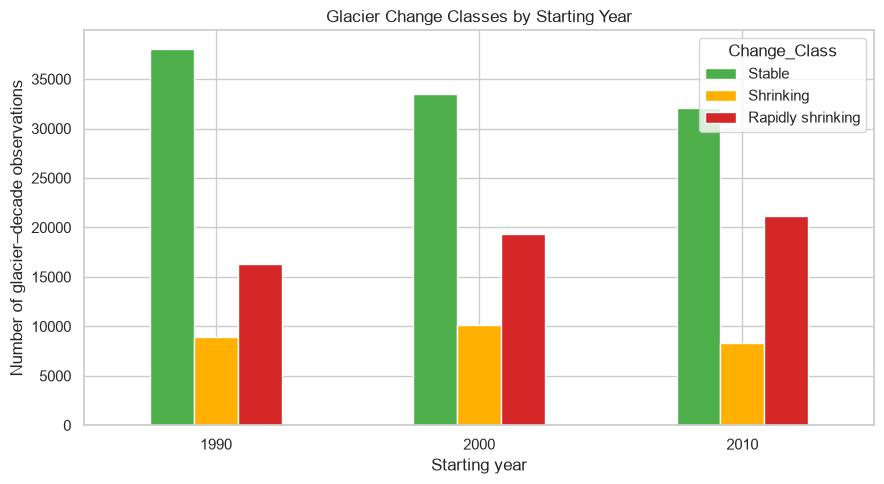

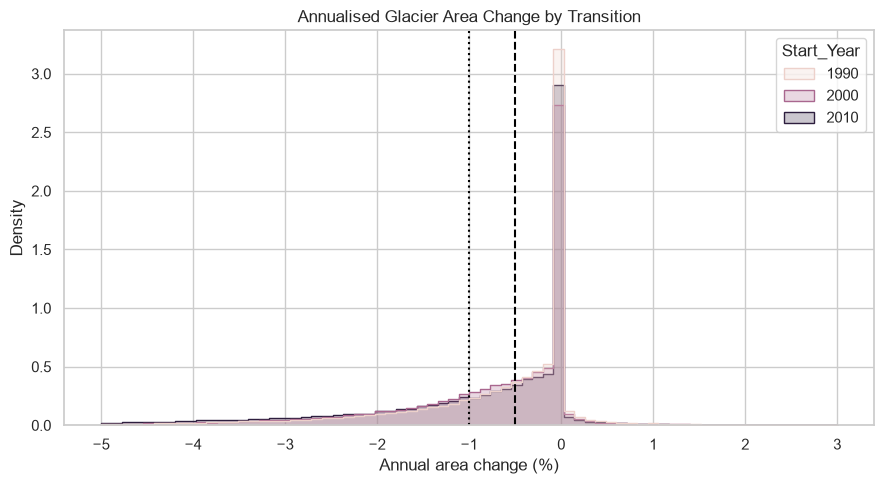

In [27]:
class_by_transition = pd.crosstab(
    glacier_decades["Start_Year"],
    glacier_decades["Change_Class"],
).reindex(columns=["Stable", "Shrinking", "Rapidly shrinking"], fill_value=0)
print(class_by_transition)

regional_class_distribution = pd.crosstab(
    glacier_decades["Mt_Range"],
    glacier_decades["Change_Class"],
).reindex(columns=["Stable", "Shrinking", "Rapidly shrinking"], fill_value=0)

display(Markdown("### Class counts by mountain range"))
display(regional_class_distribution)

plt.figure(figsize=(9, 5))
class_by_transition.plot(kind="bar", ax=plt.gca(), color=["#4daf4a", "#ffb000", "#d62728"])
plt.title("Glacier Change Classes by Starting Year")
plt.xlabel("Starting year")
plt.ylabel("Number of glacier–decade observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(
    data=glacier_decades[
        glacier_decades["Annual_Area_Change_Pct"].between(-5, 3)
    ],
    x="Annual_Area_Change_Pct",
    hue="Start_Year",
    bins=70,
    element="step",
    stat="density",
    common_norm=False,
)
plt.axvline(-0.5, color="black", linestyle="--", label="Stable threshold")
plt.axvline(-1.0, color="black", linestyle=":", label="Rapid threshold")
plt.title("Annualised Glacier Area Change by Transition")
plt.xlabel("Annual area change (%)")
plt.tight_layout()
plt.show()



## Step 8: Select starting-year predictor variables



In [28]:
numeric_features = [
    "Area_Start", "Log_Area",
    "Elv_min", "Elv_mean", "Elv_max", "Elevation_Range",
    "Slope_min", "Slope_mean", "Slope_max", "Slope_Range",
    "Latitude", "Longitude", "Aspect_sin", "Aspect_cos", "Start_Year",
    "Previous_Area_Start", "Previous_Annual_Change", "Has_Previous_History",
]

categorical_features = ["Mt_Range", "M_Basin", "Basin", "Previous_Class"]
model_features = numeric_features + categorical_features

X = glacier_decades[model_features].copy()
y = glacier_decades["Change_Class"].copy()

print("Model features:")
print(model_features)
print("\nPrediction target: Change_Class")
print("Prediction horizon: 10 years")
print("Target information excluded from predictors:")
print(["Area_End", "Decadal_Area_Change_Pct", "Annual_Area_Change_Pct", "Change_Class"])



Model features:
['Area_Start', 'Log_Area', 'Elv_min', 'Elv_mean', 'Elv_max', 'Elevation_Range', 'Slope_min', 'Slope_mean', 'Slope_max', 'Slope_Range', 'Latitude', 'Longitude', 'Aspect_sin', 'Aspect_cos', 'Start_Year', 'Previous_Area_Start', 'Previous_Annual_Change', 'Has_Previous_History', 'Mt_Range', 'M_Basin', 'Basin', 'Previous_Class']

Prediction target: Change_Class
Prediction horizon: 10 years
Target information excluded from predictors:
['Area_End', 'Decadal_Area_Change_Pct', 'Annual_Area_Change_Pct', 'Change_Class']


## Step 9: Create the strict temporal split and preprocessing pipeline



In [29]:
training_mask = glacier_decades["Start_Year"].isin([1990, 2000])
testing_mask = glacier_decades["Start_Year"] == 2010

X_train = X.loc[training_mask].copy()
y_train = y.loc[training_mask].copy()
X_test = X.loc[testing_mask].copy()
y_test = y.loc[testing_mask].copy()

training_groups = glacier_decades.loc[training_mask, "Mt_Range"].copy()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

grouped_cv = GroupKFold(n_splits=3)

print("Training observations:", len(X_train))
print("Final 2010–2020 test observations:", len(X_test))
print("Training mountain ranges:", training_groups.nunique())
print("Training class distribution:")
print(y_train.value_counts())
print("Test class distribution:")
print(y_test.value_counts())



Training observations: 126209
Final 2010–2020 test observations: 61476
Training mountain ranges: 16
Training class distribution:
Change_Class
Stable               71461
Rapidly shrinking    35629
Shrinking            19119
Name: count, dtype: int64
Test class distribution:
Change_Class
Stable               32034
Rapidly shrinking    21141
Shrinking             8301
Name: count, dtype: int64


## Step 10: Define the model-selection approach, Tune and train the three individual classifiers





In [30]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        penalty="l2",
        class_weight="balanced",
        max_iter=1000,
        random_state=42,
    )),
])

logistic_parameters = {
    "model__C": [0.1, 1.0, 10.0],
}

logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_parameters,
    scoring="f1_macro",
    cv=grouped_cv,
    n_jobs=-1,
    verbose=1,
)

logistic_search.fit(X_train, y_train, groups=training_groups)
best_logistic = logistic_search.best_estimator_
print("Best Logistic Regression parameters:", logistic_search.best_params_)
print("Best Logistic Regression grouped CV macro F1:", logistic_search.best_score_)



Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Logistic Regression parameters: {'model__C': 0.1}
Best Logistic Regression grouped CV macro F1: 0.4223986672797884


In [31]:
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
    )),
])

tree_parameters = {
    "model__max_depth": [8, 15, None],
    "model__min_samples_leaf": [5, 20],
}

tree_search = GridSearchCV(
    tree_pipeline,
    tree_parameters,
    scoring="f1_macro",
    cv=grouped_cv,
    n_jobs=-1,
    verbose=1,
)

tree_search.fit(X_train, y_train, groups=training_groups)
best_tree = tree_search.best_estimator_
print("Best Decision Tree parameters:", tree_search.best_params_)
print("Best Decision Tree grouped CV macro F1:", tree_search.best_score_)



Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Decision Tree parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 20}
Best Decision Tree grouped CV macro F1: 0.42607183634855644


In [32]:
forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )),
])

forest_parameters = {
    "model__max_depth": [15, None],
    "model__min_samples_leaf": [1, 5],
}

forest_search = GridSearchCV(
    forest_pipeline,
    forest_parameters,
    scoring="f1_macro",
    cv=grouped_cv,
    # Run folds sequentially because Random Forest already uses all CPU cores.
    # This avoids nested parallel processing and excessive memory use.
    n_jobs=1,
    verbose=1,
)

forest_search.fit(X_train, y_train, groups=training_groups)
best_forest = forest_search.best_estimator_
print("Best Random Forest parameters:", forest_search.best_params_)
print("Best Random Forest grouped CV macro F1:", forest_search.best_score_)

cv_summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Best_Grouped_CV_Macro_F1": [
        logistic_search.best_score_,
        tree_search.best_score_,
        forest_search.best_score_,
    ],
    "Best_Parameters": [
        str(logistic_search.best_params_),
        str(tree_search.best_params_),
        str(forest_search.best_params_),
    ],
})
display(Markdown("### Grouped cross-validation results"))
display(cv_summary)

# Select soft-voting weights with grouped out-of-fold training predictions.
# The 2010–2020 test period is not used in this selection.
oof_logistic_probabilities = cross_val_predict(
    best_logistic,
    X_train,
    y_train,
    groups=training_groups,
    cv=grouped_cv,
    method="predict_proba",
    n_jobs=1,
)

oof_tree_probabilities = cross_val_predict(
    best_tree,
    X_train,
    y_train,
    groups=training_groups,
    cv=grouped_cv,
    method="predict_proba",
    n_jobs=1,
)

oof_forest_probabilities = cross_val_predict(
    best_forest,
    X_train,
    y_train,
    groups=training_groups,
    cv=grouped_cv,
    method="predict_proba",
    # Each Random Forest fit already uses all CPU cores.
    n_jobs=1,
)

candidate_voting_weights = [
    (1, 1, 1), (1, 1, 2), (1, 1, 3),
    (1, 2, 2), (1, 2, 3), (2, 1, 2),
    (2, 1, 3), (1, 3, 3), (2, 2, 3),
]

voting_weight_rows = []
best_voting_weights = (1, 1, 1)
best_voting_macro_f1 = -1

for voting_weights in candidate_voting_weights:
    combined_probabilities = (
        voting_weights[0] * oof_logistic_probabilities
        + voting_weights[1] * oof_tree_probabilities
        + voting_weights[2] * oof_forest_probabilities
    ) / sum(voting_weights)

    combined_predictions = best_logistic.classes_[np.argmax(combined_probabilities, axis=1)]
    combined_macro_f1 = f1_score(y_train, combined_predictions, average="macro")

    voting_weight_rows.append({
        "Logistic_Weight": voting_weights[0],
        "Tree_Weight": voting_weights[1],
        "Forest_Weight": voting_weights[2],
        "OOF_Accuracy": accuracy_score(y_train, combined_predictions),
        "OOF_Balanced_Accuracy": balanced_accuracy_score(y_train, combined_predictions),
        "OOF_Macro_F1": combined_macro_f1,
    })

    if combined_macro_f1 > best_voting_macro_f1:
        best_voting_macro_f1 = combined_macro_f1
        best_voting_weights = voting_weights

voting_weight_results = pd.DataFrame(voting_weight_rows).sort_values(
    "OOF_Macro_F1", ascending=False
)

display(Markdown("### Soft-voting weight validation"))
display(voting_weight_results)
print("Selected soft-voting weights:", best_voting_weights)



Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Random Forest parameters: {'model__max_depth': None, 'model__min_samples_leaf': 5}
Best Random Forest grouped CV macro F1: 0.49116270474941287


### Grouped cross-validation results

,Model,Best_Grouped_CV_Macro_F1,Best_Parameters
0,Logistic Regression,0.422399,{'model__C': 0.1}
1,Decision Tree,0.426072,"{'model__max_depth': 15, 'model__min_samples_l..."
2,Random Forest,0.491163,"{'model__max_depth': None, 'model__min_samples..."


### Soft-voting weight validation

,Logistic_Weight,Tree_Weight,Forest_Weight,OOF_Accuracy,OOF_Balanced_Accuracy,OOF_Macro_F1
2,1,1,3,0.574286,0.523524,0.511185
6,2,1,3,0.568208,0.523996,0.509000
1,1,1,2,0.564817,0.519491,0.505343
5,2,1,2,0.561711,0.521955,0.505273
8,2,2,3,0.558700,0.517601,0.502024
4,1,2,3,0.558169,0.514822,0.500440
0,1,1,1,0.550080,0.513791,0.496568
3,1,2,2,0.545785,0.508425,0.492015
7,1,3,3,0.541142,0.503686,0.487540


Selected soft-voting weights: (1, 1, 3)


## Step 12: Train the hybrid soft-voting ensemble



In [33]:
soft_voting_model = VotingClassifier(
    estimators=[
        ("logistic", best_logistic),
        ("tree", best_tree),
        ("forest", best_forest),
    ],
    voting="soft",
    weights=best_voting_weights,
    n_jobs=-1,
)

soft_voting_model.fit(X_train, y_train)
print("Soft-voting ensemble fitted with grouped-CV weights:", best_voting_weights)



Soft-voting ensemble fitted with grouped-CV weights: (1, 1, 3)


## Step 13: Evaluate decade-ahead predictions on the untouched 2010–2020 period



               Model  Accuracy  Balanced_Accuracy  Macro_Precision  Macro_Recall  Macro_F1
Soft Voting Ensemble  0.568124           0.534303         0.523658      0.534303  0.516385
       Random Forest  0.574891           0.525245         0.516517      0.525245  0.514035
       Decision Tree  0.521293           0.503426         0.500812      0.503426  0.480670
 Logistic Regression  0.482514           0.507677         0.518079      0.507677  0.452802


### Logistic Regression classification report

,precision,recall,f1-score,support
Stable,0.848116,0.333115,0.478349,32034.000000
Shrinking,0.225651,0.480063,0.306999,8301.000000
Rapidly shrinking,0.480470,0.709853,0.573060,21141.000000
accuracy,0.482514,0.482514,0.482514,0.482514
macro avg,0.518079,0.507677,0.452802,61476.000000
weighted avg,0.637636,0.482514,0.487782,61476.000000


### Decision Tree classification report

,precision,recall,f1-score,support
Stable,0.754896,0.542642,0.631409,32034.000000
Shrinking,0.203954,0.451150,0.280914,8301.000000
Rapidly shrinking,0.543585,0.516485,0.529689,21141.000000
accuracy,0.521293,0.521293,0.521293,0.521293
macro avg,0.500812,0.503426,0.480670,61476.000000
weighted avg,0.607836,0.521293,0.549101,61476.000000


### Random Forest classification report

,precision,recall,f1-score,support
Stable,0.742879,0.632609,0.683324,32034.000000
Shrinking,0.237710,0.378629,0.292060,8301.000000
Rapidly shrinking,0.568963,0.564496,0.566720,21141.000000
accuracy,0.574891,0.574891,0.574891,0.574891
macro avg,0.516517,0.525245,0.514035,61476.000000
weighted avg,0.614859,0.574891,0.590393,61476.000000


### Soft-voting classification report

,precision,recall,f1-score,support
Stable,0.772907,0.586689,0.667045,32034.000000
Shrinking,0.238177,0.416817,0.303136,8301.000000
Rapidly shrinking,0.559890,0.599404,0.578974,21141.000000
accuracy,0.568124,0.568124,0.568124,0.568124
macro avg,0.523658,0.534303,0.516385,61476.000000
weighted avg,0.627449,0.568124,0.587620,61476.000000


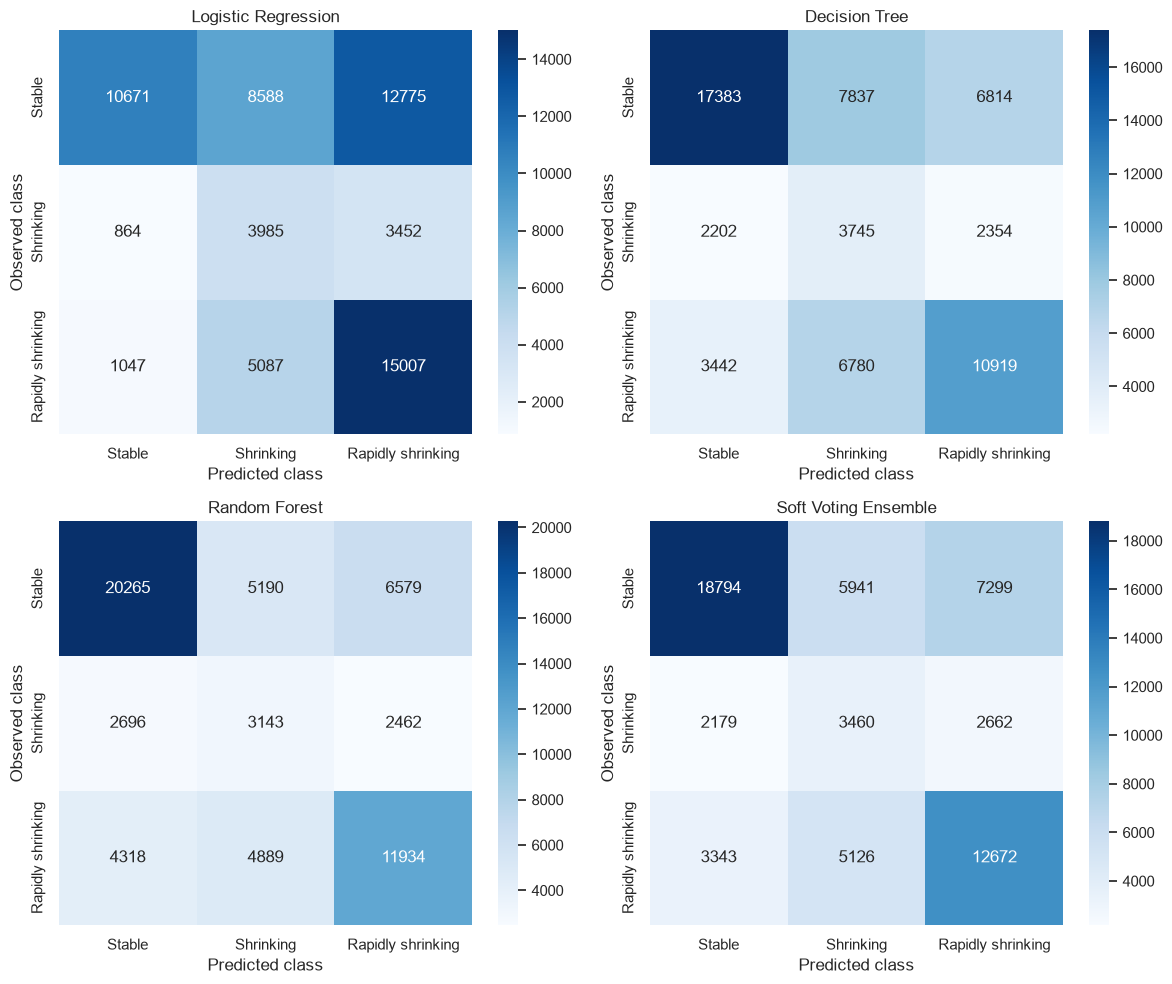

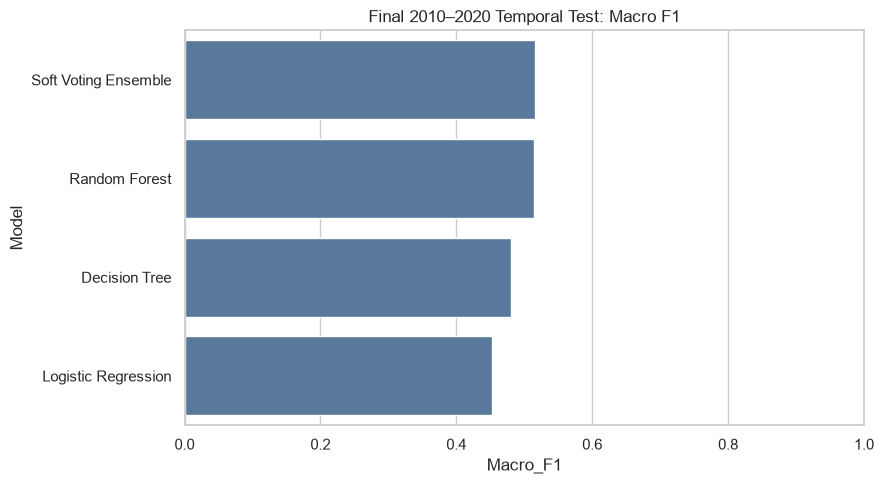

### Example 2010–2020 predictions

,GLIMS_ID,Start_Year,End_Year,Target_Period,Prediction_Horizon_Years,Mt_Range,M_Basin,Basin,Area_Start,Annual_Area_Change_Pct,Change_Class,Logistic_Prediction,Tree_Prediction,Forest_Prediction,Voting_Prediction,Probability_Rapidly_shrinking,Probability_Shrinking,Probability_Stable,Prediction_Confidence,Prediction_Uncertainty,Prediction_Correct
126209,G068019E34575N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.098,-1.020408,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.551799,0.249395,0.198806,0.551799,0.448201,True
126210,G067956E34607N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.229,0.262009,Stable,Shrinking,Rapidly shrinking,Stable,Stable,0.321701,0.336746,0.341553,0.341553,0.658447,True
126211,G067962E34609N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.092,0.434783,Stable,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.500577,0.265981,0.233442,0.500577,0.499423,False
126212,G067938E34616N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.156,1.538462,Stable,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.569194,0.243723,0.187084,0.569194,0.430806,False
126213,G067923E34615N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.322,-1.583851,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.495956,0.280371,0.223672,0.495956,0.504044,True
126214,G067876E34614N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.226,2.566372,Stable,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.618032,0.204035,0.177934,0.618032,0.381968,False
126215,G067670E34637N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.074,-3.513514,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.564741,0.227012,0.208248,0.564741,0.435259,True
126216,G067678E34639N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.047,-3.404255,Rapidly shrinking,Rapidly shrinking,Shrinking,Stable,Stable,0.369062,0.228411,0.402527,0.402527,0.597473,False
126217,G067747E34647N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.091,0.879121,Stable,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.606101,0.208733,0.185166,0.606101,0.393899,False
126218,G067663E34642N,2010,2020,2010–2020,10,Hindu Kush,Amudarya,Amudarya_5,0.076,-1.052632,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,Rapidly shrinking,0.521587,0.223294,0.255120,0.521587,0.478413,True


### Decade-ahead prediction confidence

,Voting_Prediction,Predictions,Mean_Confidence,Median_Confidence,Observed_Accuracy
0,Rapidly shrinking,22633,0.581237,0.567045,0.559890
1,Shrinking,14527,0.504934,0.491606,0.238177
2,Stable,24316,0.658471,0.663403,0.772907


In [34]:
logistic_predictions = best_logistic.predict(X_test)
tree_predictions = best_tree.predict(X_test)
forest_predictions = best_forest.predict(X_test)
voting_predictions = soft_voting_model.predict(X_test)
voting_probabilities = soft_voting_model.predict_proba(X_test)
voting_probability_classes = soft_voting_model.classes_
voting_confidence = voting_probabilities.max(axis=1)
voting_uncertainty = 1 - voting_confidence

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Soft Voting Ensemble",
]

all_predictions = [
    logistic_predictions,
    tree_predictions,
    forest_predictions,
    voting_predictions,
]

metric_rows = []

for model_name, predictions in zip(model_names, all_predictions):
    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro_Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "Macro_F1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

final_metrics = pd.DataFrame(metric_rows).sort_values("Macro_F1", ascending=False)
print(final_metrics.to_string(index=False))

class_order = ["Stable", "Shrinking", "Rapidly shrinking"]

report_logistic = pd.DataFrame(classification_report(
    y_test, logistic_predictions, labels=class_order, output_dict=True, zero_division=0
)).transpose()
report_tree = pd.DataFrame(classification_report(
    y_test, tree_predictions, labels=class_order, output_dict=True, zero_division=0
)).transpose()
report_forest = pd.DataFrame(classification_report(
    y_test, forest_predictions, labels=class_order, output_dict=True, zero_division=0
)).transpose()
report_voting = pd.DataFrame(classification_report(
    y_test, voting_predictions, labels=class_order, output_dict=True, zero_division=0
)).transpose()

display(Markdown("### Logistic Regression classification report"))
display(report_logistic)
display(Markdown("### Decision Tree classification report"))
display(report_tree)
display(Markdown("### Random Forest classification report"))
display(report_forest)
display(Markdown("### Soft-voting classification report"))
display(report_voting)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
prediction_sets = [
    ("Logistic Regression", logistic_predictions),
    ("Decision Tree", tree_predictions),
    ("Random Forest", forest_predictions),
    ("Soft Voting Ensemble", voting_predictions),
]

for axis, model_result in zip(axes.ravel(), prediction_sets):
    model_name = model_result[0]
    predictions = model_result[1]
    matrix = confusion_matrix(y_test, predictions, labels=class_order)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_order,
        yticklabels=class_order,
        ax=axis,
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Observed class")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.barplot(data=final_metrics, x="Macro_F1", y="Model", color="#4c78a8")
plt.xlim(0, 1)
plt.title("Final 2010–2020 Temporal Test: Macro F1")
plt.tight_layout()
plt.show()

test_results = glacier_decades.loc[testing_mask, [
    "GLIMS_ID", "Start_Year", "End_Year", "Target_Period",
    "Prediction_Horizon_Years", "Mt_Range", "M_Basin", "Basin", "Area_Start",
    "Annual_Area_Change_Pct", "Change_Class",
]].copy()
test_results["Logistic_Prediction"] = logistic_predictions
test_results["Tree_Prediction"] = tree_predictions
test_results["Forest_Prediction"] = forest_predictions
test_results["Voting_Prediction"] = voting_predictions

# Store the soft-voting probability for every possible class. These values show
# how strongly the model supports each decade-ahead prediction. Confidence is the
# largest class probability; uncertainty is one minus that confidence.
for class_position, class_name in enumerate(voting_probability_classes):
    safe_class_name = class_name.replace(" ", "_")
    test_results["Probability_" + safe_class_name] = voting_probabilities[:, class_position]

test_results["Prediction_Confidence"] = voting_confidence
test_results["Prediction_Uncertainty"] = voting_uncertainty
test_results["Prediction_Correct"] = (
    test_results["Voting_Prediction"] == test_results["Change_Class"]
)

confidence_summary = test_results.groupby("Voting_Prediction").agg(
    Predictions=("Voting_Prediction", "size"),
    Mean_Confidence=("Prediction_Confidence", "mean"),
    Median_Confidence=("Prediction_Confidence", "median"),
    Observed_Accuracy=("Prediction_Correct", "mean"),
).reset_index()
display(Markdown("### Example 2010–2020 predictions"))
display(test_results.head(10))
display(Markdown("### Decade-ahead prediction confidence"))
display(confidence_summary)


